# MEMBER2 - Encoding Categorical Variables

**Dataset:** Ames Housing (`train.csv`, 1,460 houses, 79 features + `SalePrice`)  
**Task:** predict the sale price of a house (regression).  
Run this notebook from the `notebooks/` folder so the `../data/raw/` paths resolve.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_style('whitegrid')
%matplotlib inline

df = pd.read_csv('../data/raw/train.csv')
test = pd.read_csv('../data/raw/test.csv')
print('train:', df.shape, '| test:', test.shape)
df.head()

train: (1460, 81) | test: (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 1. Which columns are categorical and what kind?

`MSSubClass` is stored as a number but is really a building-type *code*, so it is treated as nominal. Columns whose values have a natural order (quality scales such as `Ex > Gd > TA > Fa > Po`) are **ordinal**; the rest are **nominal**.

In [2]:
df['MSSubClass'] = df['MSSubClass'].astype(str)
cat_cols = df.select_dtypes(exclude='number').columns.tolist()

ordinal_maps = {
    'quality': ({'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5},
                ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC', 'KitchenQual',
                 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC']),
    'BsmtExposure': ({'None': 0, 'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4}, ['BsmtExposure']),
    'BsmtFinType': ({'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6}, ['BsmtFinType1', 'BsmtFinType2']),
    'GarageFinish': ({'None': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3}, ['GarageFinish']),
    'LotShape': ({'IR3': 0, 'IR2': 1, 'IR1': 2, 'Reg': 3}, ['LotShape']),
    'LandSlope': ({'Sev': 0, 'Mod': 1, 'Gtl': 2}, ['LandSlope']),
    'PavedDrive': ({'N': 0, 'P': 1, 'Y': 2}, ['PavedDrive']),
    'CentralAir': ({'N': 0, 'Y': 1}, ['CentralAir']),
}
ordinal_cols = [c for _, cols in ordinal_maps.values() for c in cols]
nominal_cols = [c for c in cat_cols if c not in ordinal_cols]
print('Categorical columns:', len(cat_cols), '| ordinal:', len(ordinal_cols), '| nominal:', len(nominal_cols))
card = df[nominal_cols].nunique().sort_values(ascending=False)
print('Highest-cardinality nominal columns:', card.head(5).to_dict())

Categorical columns: 44 | ordinal: 18 | nominal: 26
Highest-cardinality nominal columns: {'Neighborhood': 25, 'Exterior2nd': 16, 'MSSubClass': 15, 'Exterior1st': 15, 'Condition1': 9}


## 2. Encode: ordinal mapping for ordered scales, one-hot for nominal columns

In [3]:
df_enc = df.copy()
for mapping, cols in ordinal_maps.values():
    for c in cols:
        df_enc[c] = df_enc[c].fillna('None').map(mapping)

df_enc[nominal_cols] = df_enc[nominal_cols].fillna('None')
df_enc = pd.get_dummies(df_enc, columns=nominal_cols, dtype='int8')
onehot_cols = [c for c in df_enc.columns if c.startswith(tuple(n + '_' for n in nominal_cols))]
print('Columns before:', df.shape[1], '-> after encoding:', df_enc.shape[1])
print('Ordinal columns mapped to integers:', len(ordinal_cols), '| one-hot indicator columns created:', len(onehot_cols))
print('Non-numeric columns left:', df_enc.select_dtypes(exclude='number').shape[1])
display(df_enc[['ExterQual', 'KitchenQual', 'Neighborhood_NridgHt', 'Neighborhood_NAmes', 'MSZoning_RL']].head())

Columns before: 81 -> after encoding: 252
Ordinal columns mapped to integers: 18 | one-hot indicator columns created: 197
Non-numeric columns left: 0


,ExterQual,KitchenQual,Neighborhood_NridgHt,Neighborhood_NAmes,MSZoning_RL
0,4,4,0,0,1
1,3,3,0,0,1
2,4,4,0,0,1
3,3,4,0,0,1
4,4,4,0,0,1


## 3. EDA visualizations

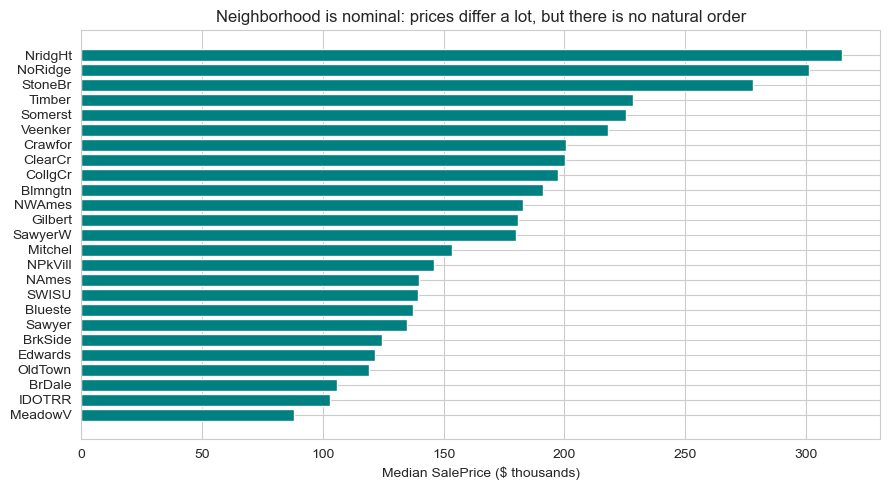

In [4]:
os.makedirs('../results/eda_visualizations/Encoding', exist_ok=True)
order = df.groupby('Neighborhood')['SalePrice'].median().sort_values()
plt.figure(figsize=(9, 5))
plt.barh(order.index, order.values / 1000, color='teal')
plt.xlabel('Median SalePrice ($ thousands)'); plt.title('Neighborhood is nominal: prices differ a lot, but there is no natural order')
plt.tight_layout()
plt.savefig('../results/eda_visualizations/Encoding/neighborhood_median_price.png', dpi=120)
plt.show()

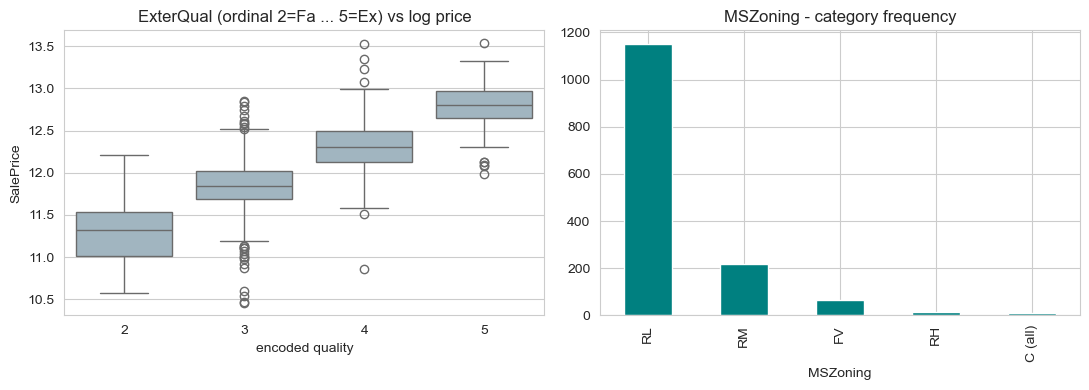

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
q = df['ExterQual'].map(ordinal_maps['quality'][0])
sns.boxplot(x=q, y=np.log1p(df['SalePrice']), ax=axes[0], color='#9CB7C5')
axes[0].set_title('ExterQual (ordinal 2=Fa ... 5=Ex) vs log price'); axes[0].set_xlabel('encoded quality')
df['MSZoning'].value_counts().plot(kind='bar', color='teal', ax=axes[1]); axes[1].set_title('MSZoning - category frequency')
plt.tight_layout()
plt.savefig('../results/eda_visualizations/Encoding/quality_vs_price.png', dpi=120)
plt.show()

### Interpretation

Of the 44 categorical columns (43 text columns plus the numeric-coded `MSSubClass`), 18 have a natural order (quality/condition scales, exposure, finish, lot shape, slope, paved drive, central air) and were mapped to integers, which keeps the order information in a single column and avoids exploding the feature count. The box plot confirms the order is meaningful: price rises steadily with exterior quality. The remaining nominal columns (e.g. `Neighborhood`, `MSZoning`, `MSSubClass`, `Exterior1st`) have no order, so they were one-hot encoded; the bar chart shows neighbourhoods differ strongly in price, so this information must be kept. One-hot encoding increases the width from 81 to 252 columns (197 new indicator columns), which is why regularised or tree-based models are used. The individual model notebooks use `OneHotEncoder(handle_unknown='ignore')` for all categorical columns inside their pipelines so categories that appear only in `test.csv` do not crash prediction.